# Lab 6: Wizualizacja danych w Matplotlib

In [1]:
#import bibliotek
import matplotlib.pyplot as plt
import numpy as np

### 1. Pierwszy wykres: liniowy i punktowy

Do rysowania funkcji ciągłych służy funkcja `plt.plot()`, natomiast do danych dyskretnych z eksperymentu najlepiej sprawdza się `plt.scatter()`.

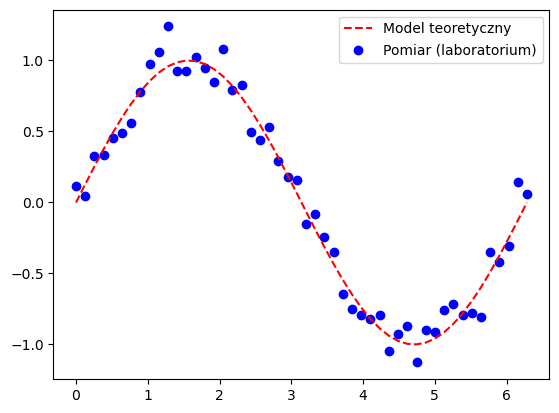

In [29]:
# Dziedzina (czas)
t = np.linspace(0, 2 * np.pi, 50)
y_teoria = np.sin(t)

# Symulowane dane eksperymentalne z szumem
y_exp = np.sin(t) + np.random.normal(0, 0.1, size=len(t))

# Tworzenie wykresu
plt.plot(t, y_teoria, label="Model teoretyczny", color="red", linestyle="--")
plt.scatter(t, y_exp, label="Pomiar (laboratorium)", color="blue", marker="o")

# Wyświetlenie
plt.legend()
plt.show()

### 2. Wykresy naukowe

Każdy wykres naukowy **powinien posiadać** opisane osie wraz z jednostkami fizycznymi, tytuł oraz opcjonalnie siatkę ułatwiającą odczyt wartości. W etykietach możemy używać formatowania LaTeX ($...$).

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


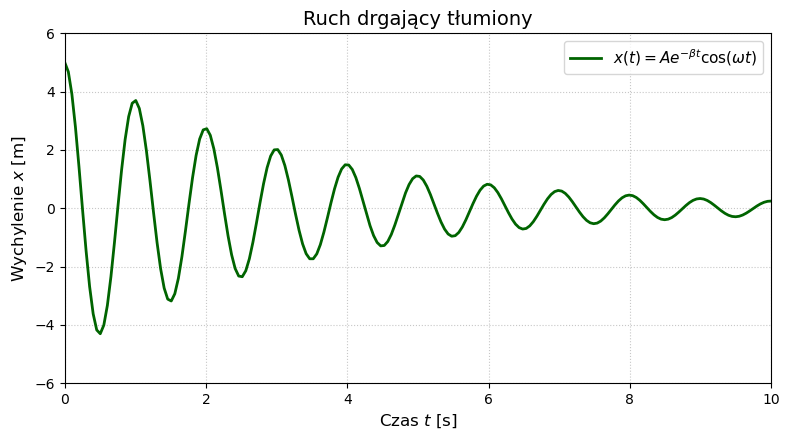

In [32]:
t = np.linspace(0, 10, 200)
x_t = 5.0 * np.exp(-0.3 * t) * np.cos(2 * np.pi * t)

plt.figure(figsize=(8, 4.5), dpi=100) # Określenie rozmiaru wykresu w calach

plt.plot(t, x_t, color="darkgreen", linewidth=2, label=r"$x(t) = A e^{-\beta t} \cos(\omega t)$")

# Opisy osi i tytuł
plt.xlabel("Czas $t$ [s]", fontsize=12)
plt.ylabel("Wychylenie $x$ [m]", fontsize=12)
plt.title("Ruch drgający tłumiony", fontsize=14)

# Siatka i zakresy
plt.grid(True, linestyle=":", alpha=0.7)
plt.xlim(0, 10)
plt.ylim(-6, 6)

plt.legend(fontsize=11, loc="upper right")
plt.tight_layout() # Automatyczne dopasowanie marginesów
plt.show()

### 3. Wizualizacja niepewności pomiarowych (`plt.errorbar`)

W fizyce punkt pomiarowy bez naniesionej niepewności (błędu) jest niepełny. Używamy funkcji `plt.errorbar()`.

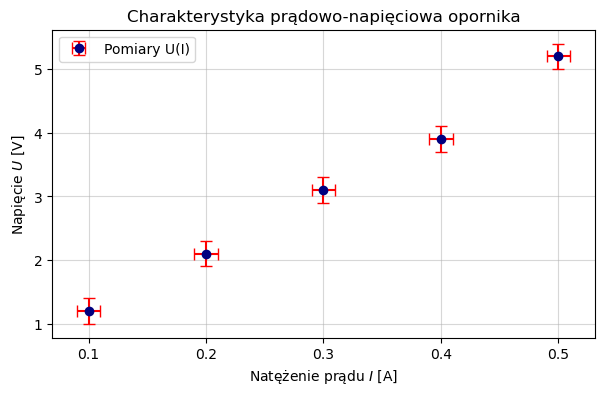

In [35]:
I = np.array([0.1, 0.2, 0.3, 0.4, 0.5])  # Prąd [A]
U = np.array([1.2, 2.1, 3.1, 3.9, 5.2])  # Napięcie [V]

niepewnosc_U = 0.2  # Stała niepewność woltomierza [V]
niepewnosc_I = 0.01 # Stała niepewność amperomierza [A]

plt.figure(figsize=(7, 4))
plt.errorbar(I, U, yerr=niepewnosc_U, xerr=niepewnosc_I, fmt='o', color='navy',
             ecolor='red', elinewidth=1.5, capsize=4, label="Pomiary U(I)")

plt.xlabel("Natężenie prądu $I$ [A]")
plt.ylabel("Napięcie $U$ [V]")
plt.title("Charakterystyka prądowo-napięciowa opornika")
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

### 4. Wykresy wielopanelowe (`plt.subplots`)

Gdy chcemy porównać dwie wielkości fizyczne w czasie (np. położenie i prędkość), tworzymy siatkę podwykresów.

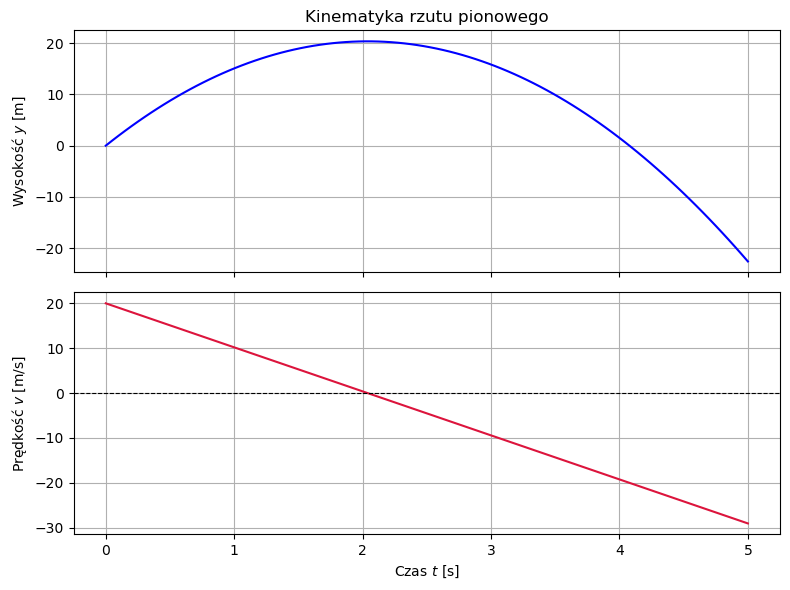

In [40]:
t = np.linspace(0, 5, 100)
y = 20 * t - 0.5 * 9.81 * t**2 # Rzut pionowy: położenie
v = 20 - 9.81 * t               # Rzut pionowy: prędkość

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Panel górny: Położenie
ax1.plot(t, y, color="blue")
ax1.set_ylabel("Wysokość $y$ [m]")
ax1.set_title("Kinematyka rzutu pionowego")
ax1.grid(True)

# Panel dolny: Prędkość
ax2.plot(t, v, color="crimson")
ax2.set_xlabel("Czas $t$ [s]")
ax2.set_ylabel("Prędkość $v$ [m/s]")
ax2.axhline(0, color="black", linestyle="--", linewidth=0.8) # Linia y=0
ax2.grid(True)

plt.tight_layout()
plt.show()

### 5. Zapisywanie wykresów do pliku

Wykresy do sprawozdań zapisujemy przed wywołaniem `plt.show()` za pomocą `plt.savefig()`.

In [20]:
# Zapis do pliku PNG w wysokiej rozdzielczości (300 DPI) oraz do pliku wektorowego PDF
# plt.savefig("wykres_wyjsciowy.png", dpi=300, bbox_inches="tight")
# plt.savefig("wykres_wyjsciowy.pdf", bbox_inches="tight")
print("Użyj plt.savefig('nazwa.png', dpi=300, bbox_inches='tight') aby zapisać wykres.")

Użyj plt.savefig('nazwa.png', dpi=300, bbox_inches='tight') aby zapisać wykres.


---
## ZADANIA DO SAMODZIELNEGO ROZWIĄZANIA

### Zadanie 1: Wykres drgań wymuszonych i rezonansu
1. Wygeneruj wektor częstości $\omega$ od $0$ do $20\ \text{rad/s}$ (200 punktów).
2. Oblicz amplitudę drgań wymuszonych ze wzoru: 
   $$A(\omega) = \frac{F_0}{\sqrt{(\omega_0^2 - \omega^2)^2 + 4\gamma^2 \omega^2}}$$
   Przyjmij $F_0 = 10$, $\omega_0 = 10\ \text{rad/s}$ oraz tłumienie $\gamma = 1.5$.
3. Narysuj wykres zależności $A(\omega)$, opisz osie (z jednostkami), dodaj siatkę oraz zaznacz punkt rezonansowy linią pionową (`plt.axvline`).

<>:6: SyntaxWarning: invalid escape sequence '\o'
<>:7: SyntaxWarning: invalid escape sequence '\o'
<>:6: SyntaxWarning: invalid escape sequence '\o'
<>:7: SyntaxWarning: invalid escape sequence '\o'
C:\Users\krzys\AppData\Local\Temp\ipykernel_12544\432263132.py:6: SyntaxWarning: invalid escape sequence '\o'
  plt.xlabel('$\omega$, rad/s')
C:\Users\krzys\AppData\Local\Temp\ipykernel_12544\432263132.py:7: SyntaxWarning: invalid escape sequence '\o'
  plt.ylabel('$A(\omega)$')


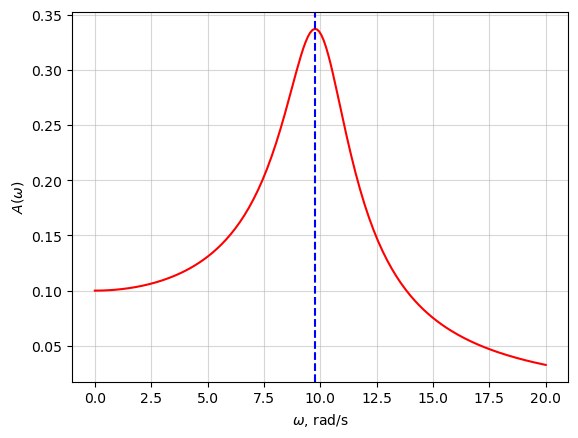

In [43]:
# Twój kod tutaj:
w = np.linspace(0, 20, 200)
F0 = 10; w0 = 10; gamma = 1.5
A = F0 / (np.sqrt((w0**2-w**2)**2 + 4*gamma**2*w**2))
plt.plot(w, A, color='red')
plt.xlabel('$\omega$, rad/s')
plt.ylabel('$A(\omega)$')
plt.grid(alpha=0.5)
plt.axvline(w[np.argmax(A)], color='blue', linestyle='--')

### Zadanie 2: Porównanie pomiaru z teorią z niepewnościami
Dane są pomiary wychylenia wahadła w zależności od czasu:
* `t_exp = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])`
* `x_exp = np.array([1.0, 0.0, -0.95, 0.05, 0.9, -0.1, -0.85])`
* Niepewność pomiaru wychylenia wynosi $\sigma_x = 0.08\ \text{m}$.

**Zadanie:**
1. Narysuj punkty pomiarowe wraz ze słupkami niepewności (`plt.errorbar`).
2. Na tym samym wykresie dorysuj ciągłą linię teorii $x(t) = \cos(\pi t)$ dla $t \in [0, 3]$ (wygeneruj płynny wektor $t$ z `np.linspace`).
3. Dodaj pełny opis wykresu (etykiety osi, legenda, siatka).

<>:11: SyntaxWarning: invalid escape sequence '\p'
<>:11: SyntaxWarning: invalid escape sequence '\p'
C:\Users\krzys\AppData\Local\Temp\ipykernel_12544\2427849034.py:11: SyntaxWarning: invalid escape sequence '\p'
  plt.ylabel('$cos(\pi t)$')


Text(0, 0.5, '$cos(\\pi t)$')

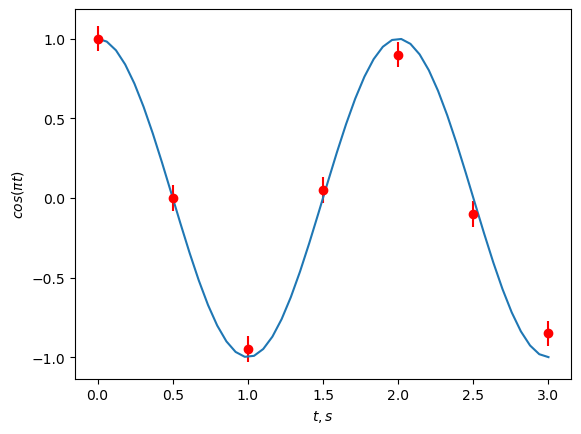

In [61]:
# Twój kod tutaj:
t_exp = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])
x_exp = np.array([1.0, 0.0, -0.95, 0.05, 0.9, -0.1, -0.85])
t = np.linspace(0, 3, 50)
x = np.cos(np.pi*t)
sigma_x = 0.08

plt.errorbar(t_exp, x_exp, yerr = sigma_x, fmt='o', color='red')
plt.plot(t, x)
plt.xlabel('$t, s$')
plt.ylabel('$cos(\pi t)$')

### Zadanie 3: Wykres dwupanelowy (Energia w ruchu harmonicznym)
Dla ciała o masie $m = 0.5\ \text{kg}$ w ruchu harmonicznym o wspólnym czasie $t \in [0, 4\pi]$:
* Położenie: $x(t) = \sin(t)$
* Prędkość: $v(t) = \cos(t)$
* Energia kinetyczna: $E_k(t) = \frac{1}{2} m v(t)^2$
* Energia potencjalna: $E_p(t) = \frac{1}{2} m x(t)^2$

**Zadanie:**
Utwórz wykres 2-panelowy (pionowy):
1. **Górny panel:** Wykres $x(t)$ oraz $v(t)$ na jednym rysunku (z legendą).
2. **Dolny panel:** Wykres $E_k(t)$, $E_p(t)$ oraz ich sumy $E_{całkowita}(t) = E_k(t) + E_p(t)$.
3. Zapewnij czytelny opis osi i wspólne dopasowanie `plt.tight_layout()`.

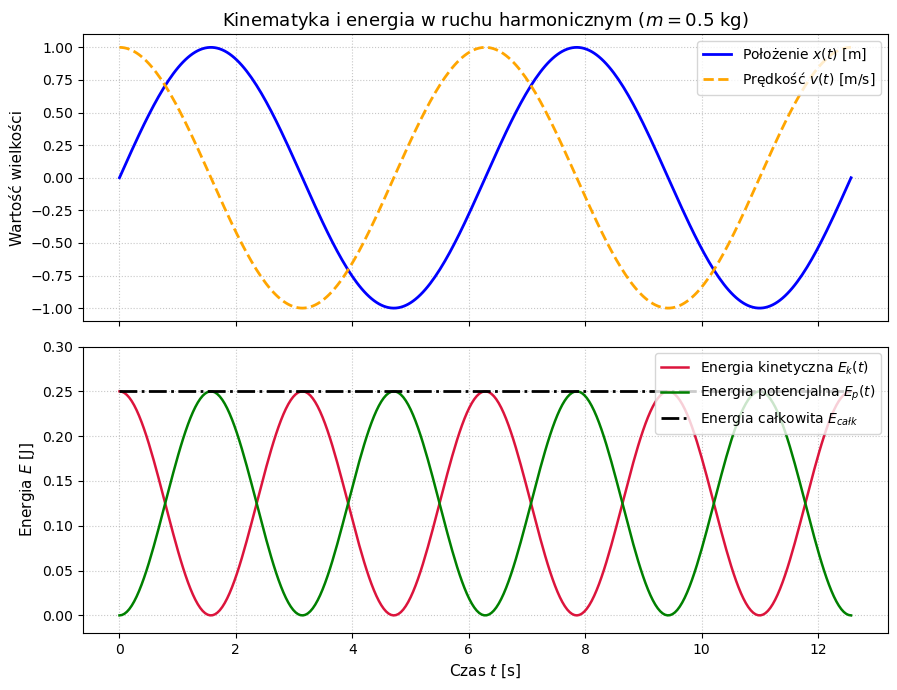

In [67]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parametry fizyczne i wektor czasu
m = 0.5  # masa [kg]
t = np.linspace(0, 4 * np.pi, 300)  # czas [s]

# 2. Obliczenia wielkości kinematycznych i energetycznych
x = np.sin(t)               # położenie [m]
v = np.cos(t)               # prędkość [m/s]
Ek = 0.5 * m * v**2         # energia kinetyczna [J]
Ep = 0.5 * m * x**2         # energia potencjalna [J]
E_calk = Ek + Ep            # energia całkowita [J]

# 3. Tworzenie wykresu 2-panelowego (pionowego)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

# Górny panel: położenie x(t) oraz prędkość v(t)
ax1.plot(t, x, label="Położenie $x(t)$ [m]", color="blue", linewidth=2)
ax1.plot(t, v, label="Prędkość $v(t)$ [m/s]", color="orange", linestyle="--", linewidth=2)
ax1.set_ylabel("Wartość wielkości", fontsize=11)
ax1.set_title("Kinematyka i energia w ruchu harmonicznym ($m = 0.5$ kg)", fontsize=13)
ax1.grid(True, linestyle=":", alpha=0.7)
ax1.legend(loc="upper right")

# Dolny panel: energie Ek(t), Ep(t) oraz ich suma
ax2.plot(t, Ek, label="Energia kinetyczna $E_k(t)$", color="crimson", linewidth=1.8)
ax2.plot(t, Ep, label="Energia potencjalna $E_p(t)$", color="green", linewidth=1.8)
ax2.plot(t, E_calk, label="Energia całkowita $E_{całk}$", color="black", linestyle="-.", linewidth=2)
ax2.set_xlabel("Czas $t$ [s]", fontsize=11)
ax2.set_ylabel("Energia $E$ [J]", fontsize=11)
ax2.set_ylim(-0.02, 0.30)  # margines poprawiający widoczność stałej linii E_całk = 0.25 J
ax2.grid(True, linestyle=":", alpha=0.7)
ax2.legend(loc="upper right")

# 4. Wspólne dopasowanie układu i wyświetlenie
plt.tight_layout()
plt.show()